# Intelligent Power Demand Forecasting: Dhanbad, Jharkhand (APU proof-of-concept)

**What this notebook does.** It takes the raw load file, cleans it, adds real Dhanbad weather and a local holiday calendar, compares several forecasting approaches fairly, and saves the best one so the backend can load it (Section 11). The API and dashboard live outside this notebook and only use the saved model.

**Headline results**
* The load file had one real problem: its timestamps were scrambled by Excel (two mixed date styles). Once fixed, the 10-minute data is complete, with no gaps.
* "Same time yesterday" is already a very strong forecast (the load is 98% correlated with itself 24 hours earlier), so any model has to beat that.
* Predicting **how much tomorrow differs from today** (a ratio) works much better than predicting the load level directly.
* The best model is a small LightGBM on that ratio. On the last three months, which were kept untouched until the end, it is off by **1.9%** on average, against **3.3%** for "same as yesterday".
* Adding weather and holidays did **not** improve accuracy on this one year of data, so the chosen model uses calendar information only. A weather-and-holiday version is saved as well.

**Choices made up front**

| Topic | Decision | Why |
|---|---|---|
| Forecast step | 30-minute blocks, 48 per day | The brief says 48 blocks. It also mentions "96 blocks" for 24 hours, which only fits 15-minute blocks, so I followed the 30-minute definition. |
| What we forecast | Total load (F1+F2+F3), plus each feeder on its own | The utility cares about the total, and feeders are useful individually. |
| 10-minute to 30-minute | Average of the three readings in each block | Load is a power level, so averaging keeps its meaning. |
| Forecast set-up | Only use load data that is at least 24 hours old | A 24-hour forecast can then be made at any time, without feeding forecasts back into themselves. |

In [2]:
# Install anything missing (safe to re-run)
import importlib.util, subprocess, sys
need = {'lightgbm': 'lightgbm', 'statsmodels': 'statsmodels', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn',
        'matplotlib': 'matplotlib', 'joblib': 'joblib', 'requests': 'requests', 'pandas': 'pandas', 'numpy': 'numpy'}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing); subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

In [3]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import json, joblib, requests, datetime as dt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from IPython.display import display
from statsmodels.tsa.stattools import acf
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 4)
# Path('data').mkdir(exist_ok=True); Path('models').mkdir(exist_ok=True)   # outputs are written here
# # Find the CSV wherever it was placed (next to the notebook, in data/, or one level up)
# CANDIDATES = [Path('data/Utility_consumption.csv'), Path('Utility_consumption.csv'),
#               Path('../data/Utility_consumption.csv'), Path('../Utility_consumption.csv')]
# DATA = next((p for p in CANDIDATES if p.exists()), None)
# if DATA is None:
#     raise FileNotFoundError('Utility_consumption.csv not found. Put it next to this notebook or in a data/ folder. Looked in: '
#                             + ', '.join(map(str, CANDIDATES)) + ' | cwd = ' + str(Path.cwd()))
# print('Using data file:', DATA.resolve())
DATA = Path('/content/Utility_consumption.csv')
LAT, LON = 23.80, 86.43           # Dhanbad, Jharkhand
FEEDERS = ['F1_132KV_PowerConsumption', 'F2_132KV_PowerConsumption', 'F3_132KV_PowerConsumption']
SEED = 42

## 1. Load the raw file and fix the timestamps

In [4]:
raw = pd.read_csv(DATA)
print(raw.shape); display(raw.head(3)); print(raw.isna().sum().sum(), 'missing cells')
# A plain pd.to_datetime fails on a large share of rows. Inspect the formats present:
raw['fmt'] = np.where(raw.Datetime.str.contains('/'), 'm/d/yyyy H:MM', 'mm-dd-yyyy HH:MM')
print(raw.fmt.value_counts())
display(raw.groupby('fmt').Datetime.agg(['first', 'last']))

(52416, 7)


,Datetime,Temperature,Humidity,WindSpeed,F1_132KV_PowerConsumption,F2_132KV_PowerConsumption,F3_132KV_PowerConsumption
0,01-01-2017 00:00,6.559,73.8,0.083,34055.69620,16128.87538,20240.96386
1,01-01-2017 00:10,6.414,74.5,0.083,29814.68354,19375.07599,20131.08434
2,01-01-2017 00:20,6.313,74.5,0.080,29128.10127,19006.68693,19668.43373


0 missing cells
fmt
m/d/yyyy H:MM       31680
mm-dd-yyyy HH:MM    20736
Name: count, dtype: int64


,first,last
fmt,,
m/d/yyyy H:MM,1/13/2017 0:00,12/30/2017 23:50
mm-dd-yyyy HH:MM,01-01-2017 00:00,12-12-2017 23:50


**What is wrong with the dates.** The `Datetime` column is written in two different styles, and both are **month-first**. The dash style (for example `02-01-2017`) is *not* day-first, so it means 1 February. Excel rewrote part of the file, which caused the mix. If the dash style were read as day-first, the first 12 days of every month would have their day and month swapped, and the data would be scrambled without any error message.

To check our reading, we sort by time and look at the step between rows. If the reading is right, time must run forward in exact 10-minute steps with no jumps.

In [5]:
raw['ts'] = pd.to_datetime(raw.Datetime.str.replace('-', '/'), format='%m/%d/%Y %H:%M')
step = raw.ts.diff().dropna()
print('monotonic:', raw.ts.is_monotonic_increasing, '| duplicates:', raw.ts.duplicated().sum())
print('step counts:', step.value_counts().to_dict())
print('range:', raw.ts.min(), '->', raw.ts.max(), '| rows:', len(raw), '| expected on full grid:',
      int((raw.ts.max() - raw.ts.min()) / pd.Timedelta('10min')) + 1)
df = raw.drop(columns=['Datetime', 'fmt']).set_index('ts').rename(
    columns={'Temperature': 'temp_file', 'Humidity': 'hum_file', 'WindSpeed': 'wind_file'})
df.index.name = 'ts'

monotonic: True | duplicates: 0
step counts: {Timedelta('0 days 00:10:00'): 52415}
range: 2017-01-01 00:00:00 -> 2017-12-30 23:50:00 | rows: 52416 | expected on full grid: 52416


The check passed: 52,416 rows, every step exactly 10 minutes, from 1 January to 30 December 2017, with no duplicates. So month-first is the right reading.

## 2. Data-quality audit

In [6]:
audit = pd.DataFrame({
    'min': df.min(), 'p01': df.quantile(.01), 'median': df.median(), 'p99': df.quantile(.99),
    'max': df.max(), 'n_max_ties': [(df[c] == df[c].max()).sum() for c in df],
    'n_repeat_prev': [(df[c].diff() == 0).sum() for c in df]}).round(1)
display(audit)
print('Covers', df.index.normalize().nunique(), 'days; 2017-12-31 is absent (series ends 12-30 23:50).')

,min,p01,median,p99,max,n_max_ties,n_repeat_prev
temp_file,3.2,6.8,18.8,33.2,40.0,1,1502
hum_file,11.3,27.3,69.9,92.0,94.8,3,3044
wind_file,0.0,0.1,0.1,4.9,6.5,1,8047
F1_132KV_PowerConsumption,13895.7,20274.8,32265.9,48099.5,52204.4,1,396
F2_132KV_PowerConsumption,8560.1,11631.7,20823.2,33734.9,37408.9,1,253
F3_132KV_PowerConsumption,5935.2,7726.3,16415.1,38722.4,47598.3,2,500


Covers 364 days; 2017-12-31 is absent (series ends 12-30 23:50).


{0.1: 30099, 4.9: 20117, 0.3: 1660, 0.2: 212}


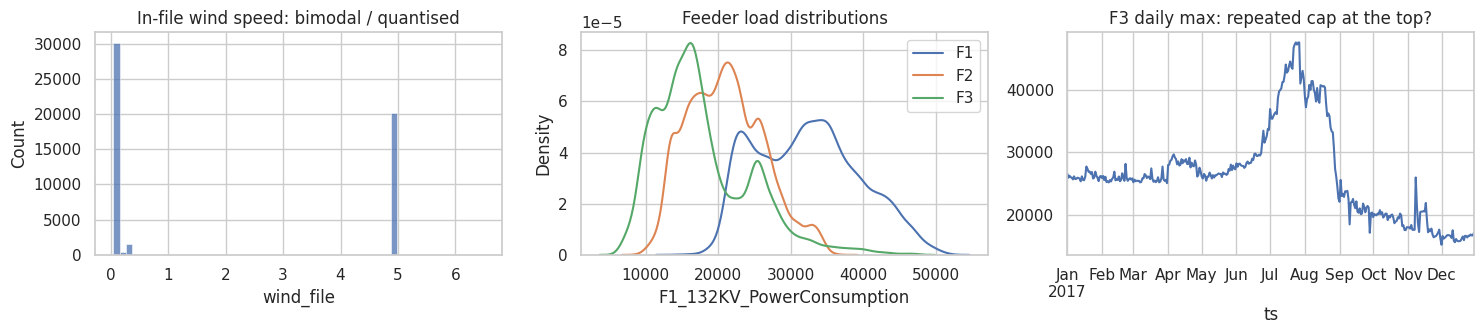

F3 rows equal to its max: 2


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(df.wind_file, bins=60, ax=ax[0]); ax[0].set_title('In-file wind speed: bimodal / quantised')
print(df.wind_file.round(1).value_counts().head(4).to_dict())
for c in FEEDERS: sns.kdeplot(df[c], ax=ax[1], label=c[:2])
ax[1].set_title('Feeder load distributions'); ax[1].legend()
df[FEEDERS[2]].resample('D').max().plot(ax=ax[2]); ax[2].set_title('F3 daily max: repeated cap at the top?')
plt.tight_layout(); plt.show()
print('F3 rows equal to its max:', (df[FEEDERS[2]] == df[FEEDERS[2]].max()).sum())

**What the audit shows**
* **No gaps.** All 52,416 ten-minute readings are present, with no missing values, duplicates, zeros or negatives. The brief warns about gaps, but after the date fix this file has none. The cleaning step below still checks for them, so it will also protect a future file that does.
* **The file's wind speed is unreliable.** It takes almost only two values (about 0.1 and about 4.9), which looks like a coarse or stuck sensor. We will not rely on it.
* **The file's own weather does not look like Dhanbad's.** Its monthly average temperature is about 12.7 °C in January and peaks in **July** (about 27 °C), while May is only about 20 °C. Dhanbad is hottest in May and June and is cooled by the July monsoon. Section 5 checks this properly against real Dhanbad weather.
* **One oddity in F3.** Its two highest readings are exactly identical (47,598.3 on 24 July and on 27 July, both at 20:10), which hints at a cap. Only two rows are involved, so we keep them.

## 3. Outlier and gap handling (Milestone 1)

**How to find bad readings without removing real peaks.** Two methods were tried, and the data decides between them.
1. **Rolling-median (Hampel) filter, about 12-hour window.** A standard choice. But electricity load rises and falls steeply every morning and evening, and this filter can mistake those normal ramps for errors.
2. **Isolated-spike detector.** It compares each reading with the average of the readings just before and after it. On a smooth ramp the difference is tiny. Only a reading that jumps away and immediately returns stands out, which is what a metering glitch looks like.

Short gaps (up to 1 hour) would be filled by interpolation, and longer gaps left empty rather than invented. Neither is needed for this file, but the code is in place.

In [8]:
full_idx = pd.date_range(df.index.min(), df.index.max(), freq='10min')
clean = df.reindex(full_idx); clean.index.name = 'ts'
print('Missing timestamps found by reindex:', int(clean[FEEDERS].isna().any(axis=1).sum()))
for c in FEEDERS: clean[c] = clean[c].interpolate(method='time', limit=6)   # <= 1 h gaps only (no-op here)

def hampel_flags(s, window=73, k=6.0):
    med = s.rolling(window, center=True, min_periods=window // 2).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=window // 2).median() * 1.4826
    return (s - med).abs() > k * mad.clip(lower=1e-9)

def spike_flags(s, k=10.0):
    r = s - (s.shift(1) + s.shift(-1)) / 2
    scale = 1.4826 * (r - r.median()).abs().median()
    return r.abs() > k * scale, r

rows = []
for c in FEEDERS:
    fs, r = spike_flags(clean[c], 10)
    rows.append({'feeder': c[:2], 'hampel_12h_k6': int(hampel_flags(clean[c]).sum()),
                 'spike_k6': int(spike_flags(clean[c], 6)[0].sum()), 'spike_k10': int(fs.sum()),
                 'spike_k10_pct_of_rows': round(100 * fs.mean(), 3),
                 'largest_dev_pct_of_level': round(100 * (r.abs()[fs] / clean[c][fs]).max(), 1)})
display(pd.DataFrame(rows).set_index('feeder'))

Missing timestamps found by reindex: 0


,hampel_12h_k6,spike_k6,spike_k10,spike_k10_pct_of_rows,largest_dev_pct_of_level
feeder,,,,,
F1,741,392,72,0.137,60.4
F2,1225,196,36,0.069,33.8
F3,4734,463,118,0.225,46.7


**Decision.** The Hampel filter flags 1% to 9% of all readings (F3 the most), mostly on ordinary ramps. Replacing those would flatten real demand peaks, so it is rejected. The isolated-spike detector flags only about 0.07% to 0.23% of readings (36 to 118 per feeder). Each one is a reading that jumps and comes straight back, which points to a glitch and not to real demand. These are replaced by interpolation between their neighbours. Everything else, including F3's high readings, is kept: F3 is simply the most jumpy feeder.

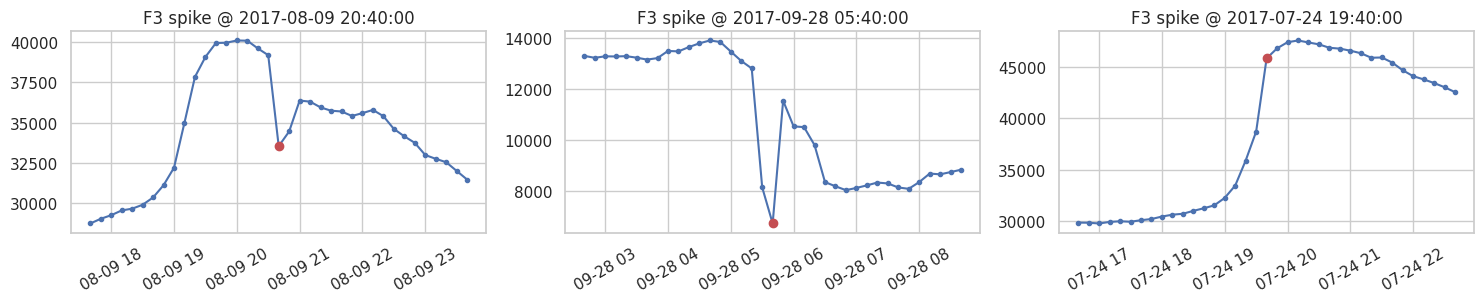

Replaced (isolated spikes, k=10): {'F1': 72, 'F2': 36, 'F3': 118}
(17472, 7) blocks = 364.0 days


,temp_file,hum_file,wind_file,F1,F2,F3,load
ts,,,,,,,
2017-01-01 00:00:00,6.428667,74.266667,0.082000,31591.898735,17567.781155,20013.493977,69173.173867
2017-01-01 00:30:00,5.965000,75.866667,0.081667,27396.455697,17883.282673,18490.602410,63770.340780
2017-01-01 01:00:00,5.605000,78.000000,0.082000,25407.594937,16627.355623,17476.626507,59511.577067


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2)); n_replaced = {}
for c in FEEDERS:
    fs, r = spike_flags(clean[c], 10); n_replaced[c[:2]] = int(fs.sum())
f3 = FEEDERS[2]; fs3, r3 = spike_flags(clean[f3], 10)
for a, t in zip(ax, r3.abs()[fs3].sort_values(ascending=False).head(3).index):
    w = clean.loc[t - pd.Timedelta('3h'): t + pd.Timedelta('3h'), f3]
    a.plot(w.index, w.values, marker='.'); a.scatter([t], [clean.loc[t, f3]], c='r', zorder=3); a.set_title('F3 spike @ ' + str(t)); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
for c in FEEDERS:
    fs, _ = spike_flags(clean[c], 10); s = clean[c].copy(); s[fs] = np.nan
    clean[c] = s.interpolate(method='time', limit=3)
print('Replaced (isolated spikes, k=10):', n_replaced)

# 10-min -> 30-min block mean
blk = clean.resample('30min').mean()
blk['load'] = blk[FEEDERS].sum(axis=1, min_count=3)
blk = blk.rename(columns={FEEDERS[0]: 'F1', FEEDERS[1]: 'F2', FEEDERS[2]: 'F3'})
print(blk.shape, 'blocks =', blk.shape[0] / 48, 'days'); display(blk.head(3))

## 4. Load EDA: what drives demand? (Milestone 1)

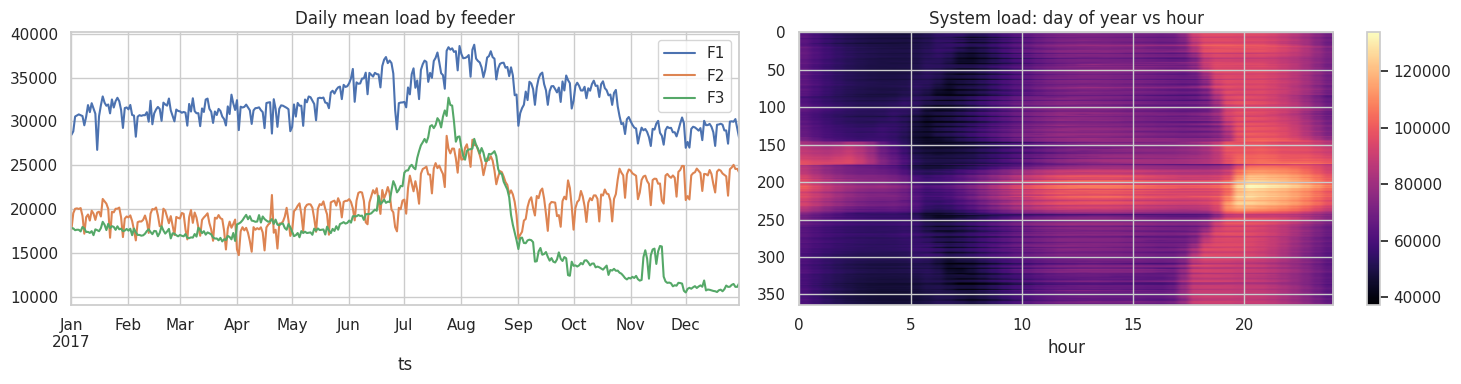

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
blk[['F1', 'F2', 'F3']].resample('D').mean().plot(ax=ax[0]); ax[0].set_title('Daily mean load by feeder')
mat = blk['load'].to_frame()
mat['day'] = mat.index.normalize(); mat['blk'] = mat.index.hour * 2 + mat.index.minute // 30
hm = mat.pivot(index='day', columns='blk', values='load')
im = ax[1].imshow(hm.values, aspect='auto', cmap='magma', extent=[0, 24, len(hm), 0])
ax[1].set_title('System load: day of year vs hour'); ax[1].set_xlabel('hour'); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

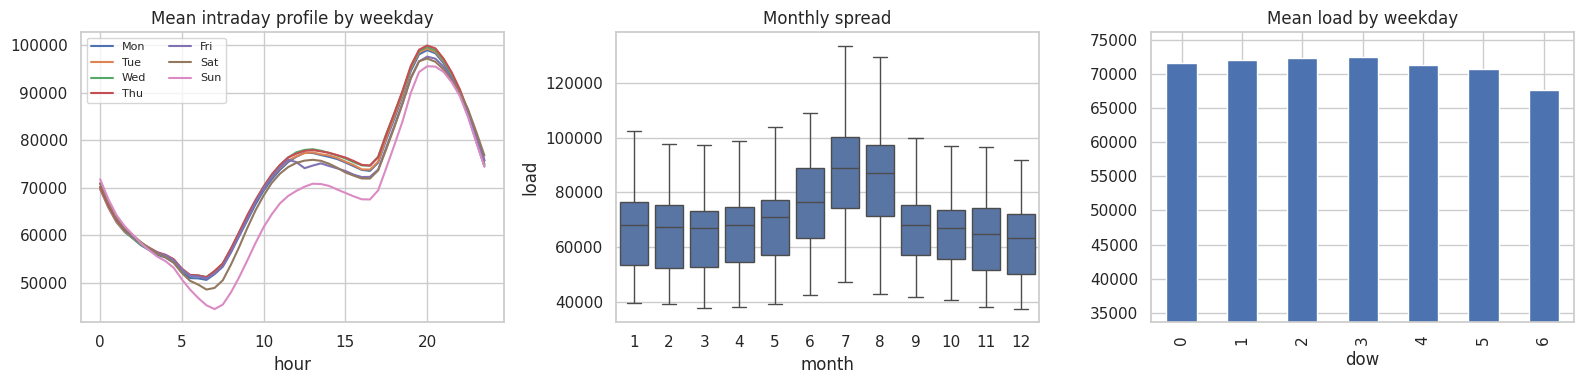

Weekend / weekday mean ratio: 0.962
Evening-peak hour: 20.0 | trough hour: 6.5


In [11]:
d = blk.copy(); d['hour'] = d.index.hour + d.index.minute / 60; d['dow'] = d.index.dayofweek; d['month'] = d.index.month
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for k, g in d.groupby('dow'): g.groupby('hour').load.mean().plot(ax=ax[0], label=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][k])
ax[0].legend(ncol=2, fontsize=8); ax[0].set_title('Mean intraday profile by weekday')
sns.boxplot(data=d, x='month', y='load', ax=ax[1], fliersize=1); ax[1].set_title('Monthly spread')
d.groupby('dow').load.mean().plot.bar(ax=ax[2]); ax[2].set_title('Mean load by weekday'); ax[2].set_ylim(d.load.min() * 0.9, None)
plt.tight_layout(); plt.show()
print('Weekend / weekday mean ratio: %.3f' % (d[d.dow >= 5].load.mean() / d[d.dow < 5].load.mean()))
print('Evening-peak hour:', d.groupby('hour').load.mean().idxmax(), '| trough hour:', d.groupby('hour').load.mean().idxmin())

{'lag 24h': np.float64(0.977), 'lag 48h': np.float64(0.966), 'lag 7d': np.float64(0.95), 'lag 12h': np.float64(-0.231)}


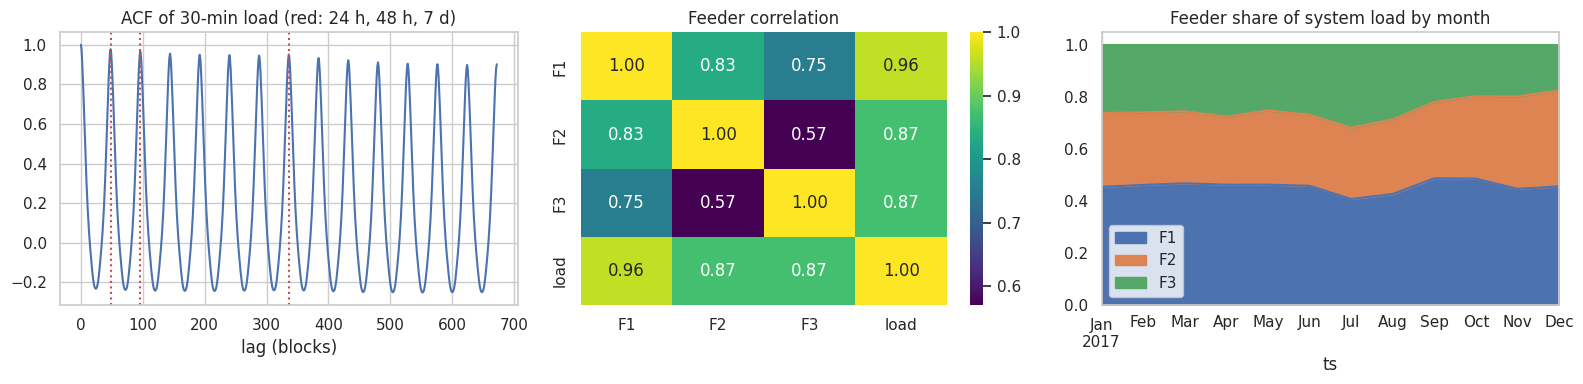

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
lags = 48 * 14
ac = acf(blk['load'].dropna(), nlags=lags, fft=True)
ax[0].plot(ac); [ax[0].axvline(x, c='r', ls=':') for x in (48, 96, 336)]
ax[0].set_title('ACF of 30-min load (red: 24 h, 48 h, 7 d)'); ax[0].set_xlabel('lag (blocks)')
print({'lag 24h': round(ac[48], 3), 'lag 48h': round(ac[96], 3), 'lag 7d': round(ac[336], 3), 'lag 12h': round(ac[24], 3)})
corr = blk[['F1', 'F2', 'F3', 'load']].corr(); sns.heatmap(corr, annot=True, fmt='.2f', cmap='viridis', ax=ax[1]); ax[1].set_title('Feeder correlation')
(blk[['F1', 'F2', 'F3']].div(blk.load, axis=0)).resample('MS').mean().plot.area(ax=ax[2]); ax[2].set_title('Feeder share of system load by month')
plt.tight_layout(); plt.show()

**What the load data tells us**
1. **Load repeats itself closely.** The load is 98% correlated with itself 24 hours earlier, and 95% with itself one week earlier. So the best clue for any time of day is the same time yesterday.
2. **A clear daily rhythm.** Demand peaks around 20:00 and is lowest around 06:30.
3. **Weekends are only a little lower.** Weekend demand is about 4% below weekday demand, so the weekday effect is real but modest.
4. **The feeders move together** (correlations 0.57 to 0.83), but their shares of the total shift from month to month, and F3 is the most jumpy. So we build one model for the total and one for each feeder, with the same set of inputs.

## 5. Weather data for Dhanbad (public API) (Milestone 2)

**Source:** the free **Open-Meteo** historical weather service (no key needed), for Dhanbad (23.80 N, 86.43 E). We take four hourly measurements: temperature, humidity, **cloud cover** and wind speed, in the Asia/Kolkata time zone. Wind speed is in km/h, as the service reports it. When the backend needs a live forecast, the same service has a forecast endpoint with identical variable names, so training data and live data look the same.

The downloaded data is saved to `data/weather_dhanbad_2017.csv`, so re-running the notebook does not need internet again. If the download ever fails, the notebook says so clearly and falls back to the weather columns inside the load file. That fallback is not Dhanbad weather, so check the `WEATHER_SOURCE` line it prints.

In [13]:
WX_CANDIDATES = [Path('data/weather_dhanbad_2017.csv'), Path('weather_dhanbad_2017.csv')]
WX_CACHE = next((p for p in WX_CANDIDATES if p.exists()), WX_CANDIDATES[0])   # reuse a saved copy if there is one

def fetch_weather(start, end):
    url = 'https://archive-api.open-meteo.com/v1/archive'
    p = dict(latitude=LAT, longitude=LON, start_date=start, end_date=end, timezone='Asia/Kolkata',
             hourly='temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m')
    r = requests.get(url, params=p, timeout=30); r.raise_for_status()
    h = pd.DataFrame(r.json()['hourly']); h['time'] = pd.to_datetime(h['time']); h = h.set_index('time')
    return h.rename(columns={'temperature_2m': 'temp', 'relative_humidity_2m': 'hum', 'cloud_cover': 'cloud', 'wind_speed_10m': 'wind'})

WEATHER_SOURCE = None
if WX_CACHE.exists():
    wx_h = pd.read_csv(WX_CACHE, index_col=0, parse_dates=True); WEATHER_SOURCE = 'open-meteo (saved copy)'
else:
    try:
        wx_h = fetch_weather(str(blk.index.min().date()), str(blk.index.max().date())); WEATHER_SOURCE = 'open-meteo (downloaded)'
    except Exception as e:
        print('!! Could not download Open-Meteo weather -> %r. FALLING BACK to the in-file weather.' % (e,))
        wx_h = None; WEATHER_SOURCE = 'IN-FILE FALLBACK (not Dhanbad!)'
    if wx_h is not None:                                    # saving the copy must never break the run
        try: WX_CACHE.parent.mkdir(parents=True, exist_ok=True); wx_h.to_csv(WX_CACHE)
        except Exception as e: print('Note: downloaded fine, but could not save a copy (%r)' % (e,))
print('WEATHER_SOURCE =', WEATHER_SOURCE)

WEATHER_SOURCE = open-meteo (downloaded)


In [14]:
if wx_h is not None:
    wx = wx_h.resample('30min').interpolate('time').reindex(blk.index).interpolate('time').ffill().bfill()
else:
    wx = blk[['temp_file', 'hum_file', 'wind_file']].rename(columns={'temp_file': 'temp', 'hum_file': 'hum', 'wind_file': 'wind'}).copy()
    wx['cloud'] = np.nan
HAVE_CLOUD = wx['cloud'].notna().any()
data = blk[['F1', 'F2', 'F3', 'load']].join(wx[['temp', 'hum', 'cloud', 'wind']])
print('cloud cover available:', HAVE_CLOUD); display(data.describe().T.round(2))

cloud cover available: True


,count,mean,std,min,25%,50%,75%,max
F1,17472.0,32346.11,7113.37,13915.95,26337.35,32287.78,37313.29,52102.11
F2,17472.0,21042.50,5191.66,8674.95,16995.09,20836.36,24725.11,36424.50
F3,17472.0,17835.81,6612.89,6096.52,13148.95,16414.24,21642.06,47509.96
load,17472.0,71224.42,17110.52,37318.41,56482.73,69811.21,83741.42,133772.09
temp,17472.0,25.46,5.84,7.70,22.05,26.10,28.90,41.40
hum,17472.0,69.52,21.87,8.00,54.50,75.00,87.50,100.00
cloud,17472.0,44.03,42.31,0.00,0.00,31.00,95.50,100.00
wind,17472.0,8.25,4.06,0.00,5.40,7.60,10.40,32.80


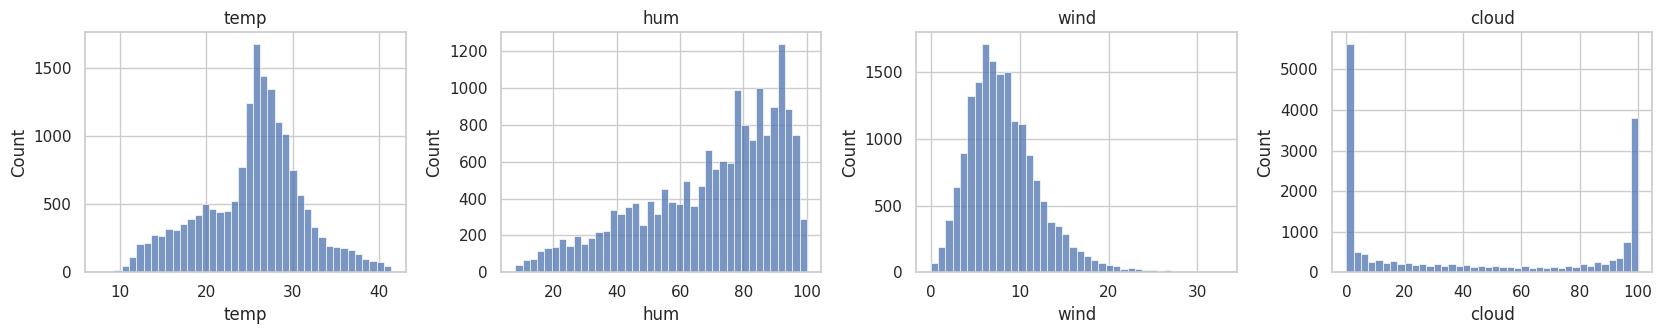

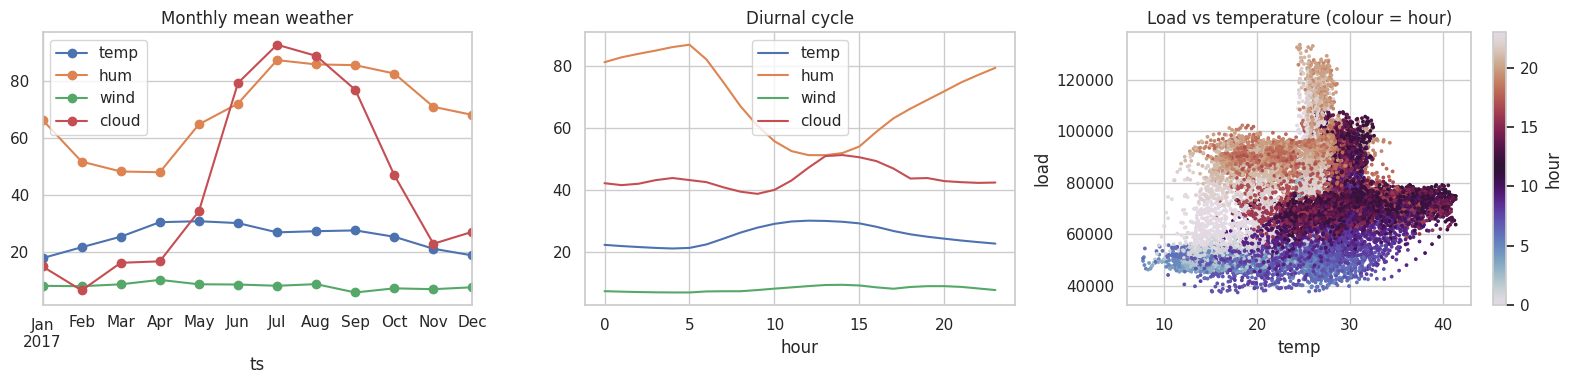

Correlation with load: {'temp': 0.255, 'hum': 0.012, 'wind': 0.15, 'cloud': 0.298}
Corr(temp, load residual after weekday-hour profile): 0.23


In [15]:
# Weather EDA: distributions, seasonality, diurnal cycle, relation to load
w = data.copy(); w['hour'] = w.index.hour
cols = ['temp', 'hum', 'wind'] + (['cloud'] if HAVE_CLOUD else [])
fig, ax = plt.subplots(1, len(cols), figsize=(4.2 * len(cols), 3.5))
for a, c in zip(np.atleast_1d(ax), cols): sns.histplot(w[c], bins=40, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
w[cols].resample('MS').mean().plot(ax=ax[0], marker='o'); ax[0].set_title('Monthly mean weather')
w.groupby('hour')[cols].mean().plot(ax=ax[1]); ax[1].set_title('Diurnal cycle')
sc = ax[2].scatter(w.temp, w.load, c=w.hour, s=3, cmap='twilight'); plt.colorbar(sc, ax=ax[2], label='hour')
ax[2].set_xlabel('temp'); ax[2].set_ylabel('load'); ax[2].set_title('Load vs temperature (colour = hour)')
plt.tight_layout(); plt.show()
cm = w[cols + ['load']].corr()['load'].drop('load').round(3); print('Correlation with load:', cm.to_dict())
# After removing the daily/weekly shape, how much does weather add? Correlate residuals vs same-block weekday mean.
prof = w.groupby([w.index.dayofweek, w.index.hour, w.index.minute]).load.transform('mean')
resid = (w.load - prof); print('Corr(temp, load residual after weekday-hour profile):', round(resid.corr(w.temp), 3))

corr(API temp, in-file temp): 0.559 | mean API 25.5 vs file 18.8


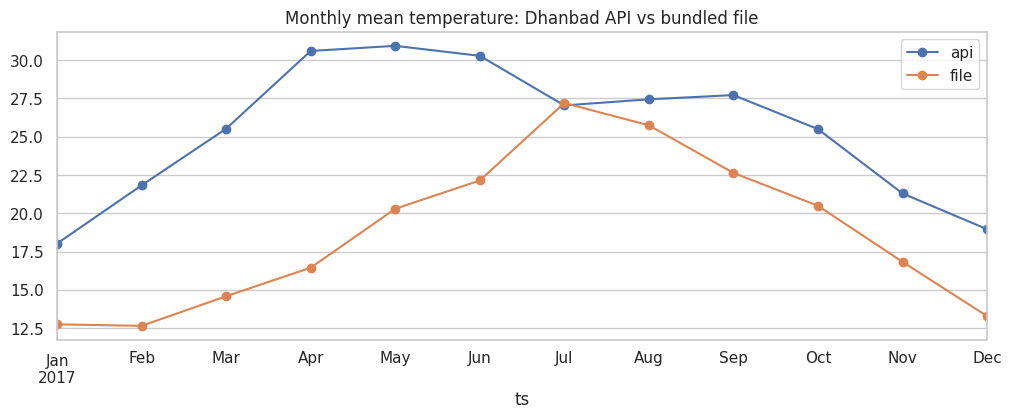

In [16]:
# If the API weather is loaded, compare it with the bundled weather (sanity check on the "wrong location" suspicion).
if WEATHER_SOURCE.startswith('open-meteo'):
    cmp = pd.DataFrame({'api': wx.temp, 'file': blk.temp_file}).dropna()
    print('corr(API temp, in-file temp):', round(cmp.corr().iloc[0, 1], 3), '| mean API %.1f vs file %.1f' % (cmp.api.mean(), cmp.file.mean()))
    cmp.resample('MS').mean().plot(marker='o', title='Monthly mean temperature: Dhanbad API vs bundled file'); plt.show()
else:
    print('Skipped: API weather not loaded in this run.')

**What the weather data shows**
* **The file's own weather is not Dhanbad's.** Over the same year the Dhanbad temperature averages **25.5 °C**, against **18.8 °C** in the load file, and the two track each other only loosely (correlation 0.56). That confirms the doubt from Section 2. We use the Dhanbad weather from the service and keep the file's columns out of the model.
* **Weather and load are only loosely linked here.** Correlation with load is 0.30 for cloud cover, 0.26 for temperature, 0.15 for wind and about 0 for humidity. Even after removing the normal weekday and time-of-day pattern, temperature explains little (correlation 0.23). Part of the cloud and temperature link is just the seasons moving together with load.
* **A possible reason.** The load file's own weather looks like a different climate from Dhanbad's. If the load was recorded somewhere else, Dhanbad's weather would naturally explain little of it. We cannot confirm this, but it fits the weak links above and the model results later.

## 6. Localised holiday calendar: Dhanbad / Jharkhand (Milestone 2)

A national holiday list is not enough for Dhanbad. The coal belt has its own big days: **Chhath Puja, Karma Puja, Sarhul, Sohrai, Vishwakarma Puja** (the workshop and industry festival), **Durga and Kali Puja**, and **Jharkhand Foundation Day** (15 November). Each holiday carries a category, so the model can treat different types differently:

* `national`: national public holidays
* `festival`: big regional festivals
* `tribal`: Jharkhand tribal and state days (Sarhul, Karma Puja, Sohrai, Hul Diwas, Foundation Day)
* `industrial`: days when coal and industrial units usually cut shifts (Vishwakarma Puja, Labour Day)
* `religious_minority`: Eid, Muharram, Christmas, Good Friday and similar

**Please note.** I compiled these dates from the Jharkhand government holiday pattern and standard religious calendars, without access to the official notification. Festival dates that follow the moon (Sarhul, Karma Puja, Chhath, Eid) should be checked against the official Jharkhand list before anyone relies on them. A few 2026 dates are included for the live dashboard and are approximate.

44 entries


category,festival,religious_minority,tribal,national,industrial
count,22,9,6,5,2


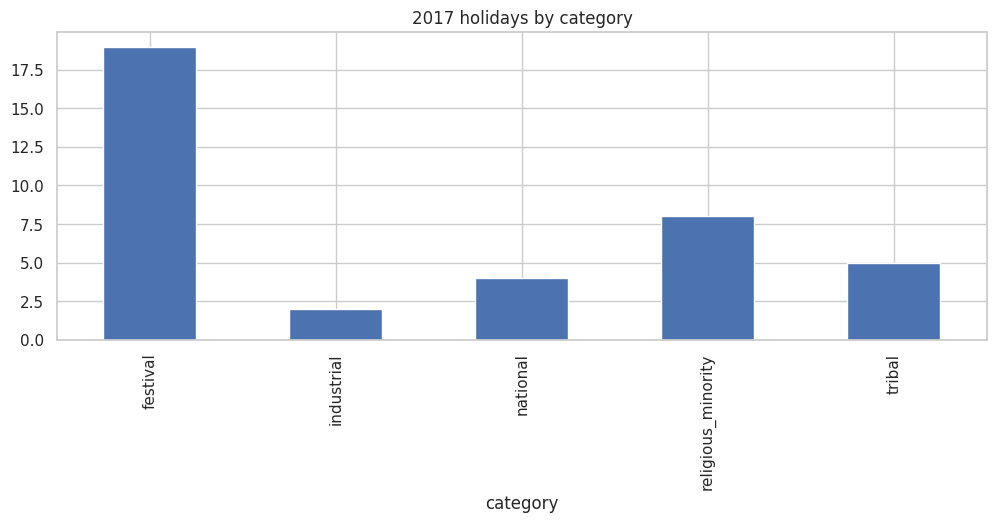

In [17]:
H = [  # (date, name, category)  -- 2017 (training year)
 ('2017-01-01','New Year','national'),('2017-01-14','Makar Sankranti / Tusu Parv','festival'),('2017-01-26','Republic Day','national'),
 ('2017-02-01','Vasant Panchami (Saraswati Puja)','festival'),('2017-02-24','Maha Shivratri','festival'),
 ('2017-03-13','Holi','festival'),('2017-03-30','Sarhul','tribal'),('2017-04-04','Ram Navami','festival'),
 ('2017-04-09','Mahavir Jayanti','religious_minority'),('2017-04-14','Good Friday','religious_minority'),
 ('2017-05-01','Labour Day / May Day','industrial'),('2017-05-10','Buddha Purnima','religious_minority'),
 ('2017-06-26','Eid-ul-Fitr','religious_minority'),('2017-06-30','Hul Diwas','tribal'),
 ('2017-08-07','Raksha Bandhan','festival'),('2017-08-15','Independence Day','national'),('2017-08-15','Janmashtami','festival'),
 ('2017-08-25','Ganesh Chaturthi','festival'),('2017-09-01','Karma Puja','tribal'),('2017-09-02','Eid-ul-Adha (Bakrid)','religious_minority'),
 ('2017-09-17','Vishwakarma Puja','industrial'),
 ('2017-09-26','Durga Puja (Shashthi)','festival'),('2017-09-27','Durga Puja (Saptami)','festival'),('2017-09-28','Durga Puja (Ashtami)','festival'),
 ('2017-09-29','Durga Puja (Navami)','festival'),('2017-09-30','Vijayadashami (Dussehra)','festival'),
 ('2017-10-01','Muharram (Ashura)','religious_minority'),('2017-10-02','Gandhi Jayanti','national'),
 ('2017-10-19','Diwali / Kali Puja','festival'),('2017-10-20','Sohrai / Govardhan Puja','tribal'),('2017-10-21','Bhai Dooj','festival'),
 ('2017-10-24','Chhath Puja (Nahay-Khay)','festival'),('2017-10-25','Chhath Puja (Kharna)','festival'),
 ('2017-10-26','Chhath Puja (Sandhya Arghya)','festival'),('2017-10-27','Chhath Puja (Usha Arghya)','festival'),
 ('2017-11-04','Guru Nanak Jayanti','religious_minority'),('2017-11-15','Jharkhand Foundation Day / Birsa Munda Jayanti','tribal'),
 ('2017-12-25','Christmas','religious_minority'),
]
# Upcoming-year entries for the serving layer (verify yearly against the official notification)
H += [('2026-10-02','Gandhi Jayanti','national'),('2026-10-20','Dussehra (Vijayadashami)','festival'),
      ('2026-11-08','Diwali / Kali Puja','festival'),('2026-11-15','Jharkhand Foundation Day','tribal'),
      ('2026-11-15','Chhath Puja (Sandhya Arghya, approx.)','festival'),('2026-12-25','Christmas','religious_minority')]
hol = pd.DataFrame(H, columns=['date', 'name', 'category']); hol['date'] = pd.to_datetime(hol['date'])
hol.to_csv('data/holidays_dhanbad.csv', index=False)
print(len(hol), 'entries'); display(hol.category.value_counts().to_frame().T)
hol[hol.date.dt.year == 2017].groupby('category').size().plot.bar(title='2017 holidays by category'); plt.show()

In [18]:
def holiday_frame(index, hol):
    # Per-day holiday features for any DatetimeIndex (reused at serving time).
    days = pd.DatetimeIndex(index.normalize().unique())
    hd = hol.groupby('date').category.agg(set)
    f = pd.DataFrame(index=days)
    f['is_hol'] = f.index.isin(hd.index).astype(int)
    for cat in ['national', 'festival', 'tribal', 'industrial', 'religious_minority']:
        f['hol_' + cat] = [int(d in hd.index and cat in hd[d]) for d in f.index]
    hd_days = np.sort(hol.date.unique()).astype('datetime64[D]')
    dd = f.index.values.astype('datetime64[D]')
    to_, since_ = [], []
    for d in dd:
        fut = hd_days[hd_days >= d]; past = hd_days[hd_days <= d]
        to_.append(min(int((fut[0] - d).astype(int)), 7) if len(fut) else 7)
        since_.append(min(int((d - past[-1]).astype(int)), 7) if len(past) else 7)
    f['days_to_hol'] = to_; f['days_since_hol'] = since_
    big = hol[hol['name'].str.contains('Diwali|Durga|Chhath|Holi|Dussehra|Vijayadashami')].date.values.astype('datetime64[D]')
    f['big_festival'] = [int(np.any(np.abs((big - d).astype(int)) <= 1)) for d in dd]
    return f
hf = holiday_frame(data.index, hol[hol.date.dt.year == 2017])
hf.head()

,is_hol,hol_national,hol_festival,hol_tribal,hol_industrial,hol_religious_minority,days_to_hol,days_since_hol,big_festival
ts,,,,,,,,,
2017-01-01,1,1,0,0,0,0,0,0,0
2017-01-02,0,0,0,0,0,0,7,1,0
2017-01-03,0,0,0,0,0,0,7,2,0
2017-01-04,0,0,0,0,0,0,7,3,0
2017-01-05,0,0,0,0,0,0,7,4,0


,count,mean,std
category,,,
festival,19,0.26,1.99
industrial,2,-6.40,1.13
national,4,1.08,2.68
religious_minority,8,-3.30,6.76
tribal,5,-5.58,8.98


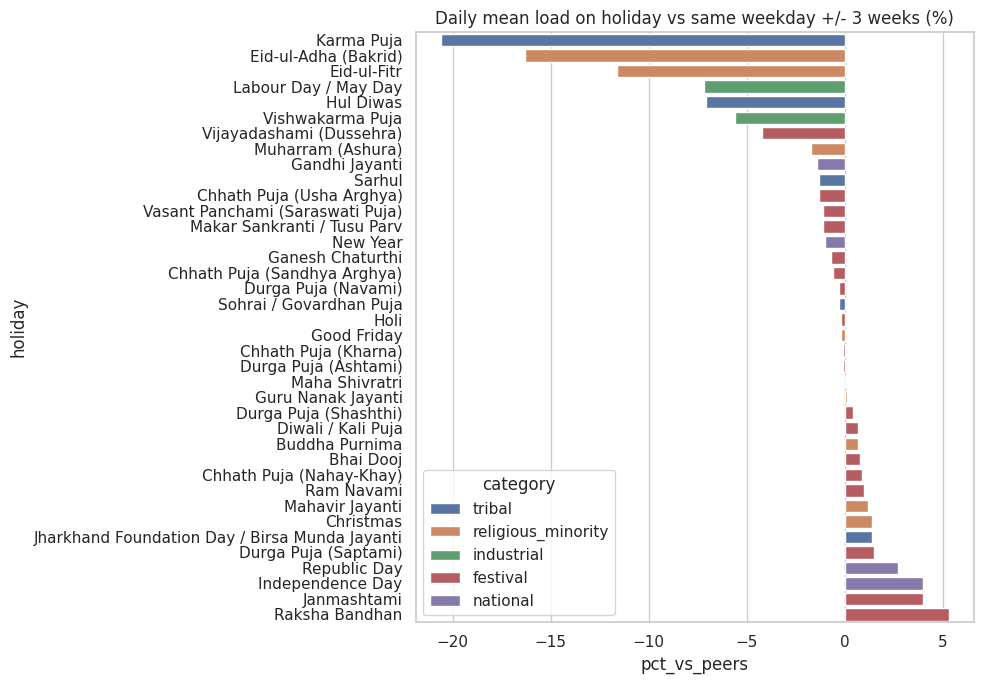

In [19]:
# Does the load actually move on those days? Compare each holiday with same-weekday non-holiday days in a +/-3-week window.
daily = data['load'].resample('D').mean(); rows = []
for _, r in hol[hol.date.dt.year == 2017].iterrows():
    d0 = r.date
    if d0 not in daily.index: continue
    peers = [d0 + pd.Timedelta(weeks=k) for k in (-3, -2, -1, 1, 2, 3)]
    peers = [p for p in peers if p in daily.index and p not in set(hol.date)]
    if len(peers) >= 2: rows.append((r['name'], r.category, d0.day_name()[:3], daily[d0] / daily[peers].mean() - 1))
imp = pd.DataFrame(rows, columns=['holiday', 'category', 'dow', 'pct_vs_peers']).sort_values('pct_vs_peers')
imp['pct_vs_peers'] = (imp.pct_vs_peers * 100).round(1)
display(imp.groupby('category').pct_vs_peers.agg(['count', 'mean', 'std']).round(2))
fig, ax = plt.subplots(figsize=(10, 7)); sns.barplot(data=imp, y='holiday', x='pct_vs_peers', hue='category', dodge=False, ax=ax)
ax.set_title('Daily mean load on holiday vs same weekday +/- 3 weeks (%)'); plt.tight_layout(); plt.show()

**What the holiday chart shows.** Each holiday's average daily load is compared with the same weekday in the three weeks before and after. Big festivals show almost no change on average (+0.3%), national holidays are slightly higher (+1.1%), and **tribal, industrial and minority-religion holidays show dips of about 3% to 6%**. There are very few examples in each group (2 industrial, 5 tribal, 8 minority-religion), and the spread is wide, so these are hints and not firm facts. We keep the categories coarse so each has as many examples as possible, and later we test directly whether holiday information improves the forecast.

## 7. Feature engineering (Milestone 2)

Every input must be known **at the time the forecast is made, for the next 24 hours**. The design rests on one idea:

> **Predict the ratio `load now / load at the same time yesterday`, instead of the load itself.**

Why: a tree-based model can only predict values it has seen before. When demand moves into a range it has not seen (as it does in summer), predicting the level fails. A ratio such as "5% higher than yesterday" stays in the same range all year. Section 8 tests this idea with numbers instead of assuming it.

| Group | What is in it | Why it is known in advance |
|---|---|---|
| Calendar | time of day, day of week, weekend flag (as sine/cosine curves too) | fixed by the calendar |
| Weather | temperature, humidity, cloud cover, wind, and how much they change from yesterday and last week, plus cooling/heating degrees | from a weather forecast |
| Holiday | is it a holiday, which type, big festival, days to/since the nearest holiday, was yesterday or last week a holiday | fixed by the calendar |
| Load history, as ratios | last week's and the day before's load, relative to yesterday's | all at least 24 hours old |
| Baseline (not an input) | load at the same time yesterday | the ratio target is measured against it |

No month or day-of-year input is used. With a single year of data, those would let the model memorise the year instead of learning real patterns.

In [20]:
def build_features(d, hf, target='load', use_cloud=True):
    X = pd.DataFrame(index=d.index)
    blk_ = d.index.hour * 2 + d.index.minute // 30
    X['block'] = blk_; X['dow'] = d.index.dayofweek; X['is_weekend'] = (X.dow >= 5).astype(int)
    X['blk_sin'] = np.sin(2 * np.pi * blk_ / 48); X['blk_cos'] = np.cos(2 * np.pi * blk_ / 48)
    X['dow_sin'] = np.sin(2 * np.pi * X.dow / 7); X['dow_cos'] = np.cos(2 * np.pi * X.dow / 7)
    # weather (known for the target time from a forecast)
    X['temp'] = d.temp; X['hum'] = d.hum; X['wind'] = d.wind
    if use_cloud and 'cloud' in d and d.cloud.notna().any(): X['cloud'] = d.cloud
    X['temp_roll24'] = d.temp.rolling(48, min_periods=1).mean()
    X['temp_d24'] = d.temp - d.temp.shift(48); X['hum_d24'] = d.hum - d.hum.shift(48); X['wind_d24'] = d.wind - d.wind.shift(48)
    X['temp_d168'] = d.temp - d.temp.shift(336)
    X['cdd'] = (d.temp - 24).clip(lower=0); X['hdd'] = (18 - d.temp).clip(lower=0); X['temp_x_hum'] = d.temp * d.hum / 100
    # holidays (daily -> block)
    h = hf.reindex(d.index.normalize()).set_index(d.index)
    for c in h: X[c] = h[c].values
    X['hol_lag48'] = X['is_hol'].shift(48); X['hol_lag336'] = X['is_hol'].shift(336)
    # load lags, all >= 24 h
    y = d[target]
    X['lag48'] = y.shift(48); X['lag96'] = y.shift(96); X['lag336'] = y.shift(336)
    stack = pd.concat([y.shift(48 * k) for k in range(1, 8)], axis=1)
    X['same_blk_mean7d'] = stack.mean(axis=1, skipna=False); X['same_blk_std7d'] = stack.std(axis=1, skipna=False)
    X['prev_day_mean'] = y.shift(48).rolling(48).mean(); X['prev_day_max'] = y.shift(48).rolling(48).max()
    # scale-free versions of the lags (what the final model actually uses)
    X['r96'] = X.lag96 / X.lag48; X['r336'] = X.lag336 / X.lag48; X['rmean7'] = X.same_blk_mean7d / X.lag48
    X['rday'] = X.prev_day_mean / X.lag48; X['rmax'] = X.prev_day_max / X.lag48; X['rstd7'] = X.same_blk_std7d / X.same_blk_mean7d
    return X

GROUPS = {
 'calendar': ['block', 'dow', 'is_weekend', 'blk_sin', 'blk_cos', 'dow_sin', 'dow_cos'],
 'weather':  ['temp', 'hum', 'wind', 'cloud', 'temp_roll24', 'temp_d24', 'hum_d24', 'wind_d24', 'temp_d168', 'cdd', 'hdd', 'temp_x_hum'],
 'holiday':  ['is_hol', 'hol_national', 'hol_festival', 'hol_tribal', 'hol_industrial', 'hol_religious_minority',
              'big_festival', 'days_to_hol', 'days_since_hol', 'hol_lag48', 'hol_lag336'],
 'lags':     ['r96', 'r336', 'rmean7', 'rday', 'rmax', 'rstd7'],
}
ABS_LAGS = ['lag48', 'lag96', 'lag336', 'same_blk_mean7d', 'same_blk_std7d', 'prev_day_mean', 'prev_day_max']  # absolute levels, used only by the comparison model
X_all = build_features(data, hf, 'load', use_cloud=HAVE_CLOUD)
GROUPS = {g: [c for c in cs if c in X_all] for g, cs in GROUPS.items()}
ALL_FEATS = sum(GROUPS.values(), [])
valid = X_all[ALL_FEATS + ABS_LAGS].notna().all(axis=1) & data['load'].notna()
print('model features:', len(ALL_FEATS), {g: len(c) for g, c in GROUPS.items()}, '| usable rows:', int(valid.sum()), 'of', len(X_all), '(first 7 days lost to the 7-day lag)')

model features: 36 {'calendar': 7, 'weather': 12, 'holiday': 11, 'lags': 6} | usable rows: 17136 of 17472 (first 7 days lost to the 7-day lag)


ratio target: mean 1.001, std 0.054, 1%-99% = 0.86 to 1.19


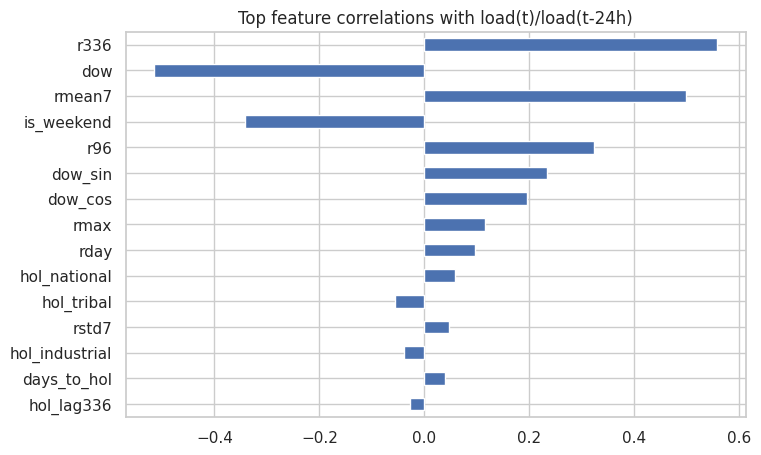

In [21]:
# Sanity check: does the engineered ratio target carry signal the features can explain?
ratio = (data.load / X_all.lag48)[valid]
print('ratio target: mean %.3f, std %.3f, 1%%-99%% = %.2f to %.2f' % (ratio.mean(), ratio.std(), ratio.quantile(.01), ratio.quantile(.99)))
tmp = X_all.loc[valid, ALL_FEATS].assign(ratio=ratio)
corr = tmp.corr()['ratio'].drop('ratio').sort_values(key=abs, ascending=False)
corr.head(15).plot.barh(figsize=(8, 5)).invert_yaxis(); plt.title('Top feature correlations with load(t)/load(t-24h)'); plt.show()

**Quick check of the target.** The ratio `load now / load yesterday` averages 1.00, and its typical day-to-day spread is about 5%. 98% of values fall between 0.86 and 1.19. That is a small, stable range, which is exactly what makes it an easier thing for the model to learn than the raw load.

## 8. Model-architecture justification (Milestone 2): evidence first, then choice

**Approaches considered**

| Approach | Good | Not so good for this data |
|---|---|---|
| Copy yesterday / last week | Free, and the bar every model must beat | Ignores weekends, weather and holidays |
| SARIMAX / Prophet-style | Easy to interpret | Needs several years to learn yearly patterns; we have one |
| Ridge (linear) regression | Simple and stable | Cannot capture "it depends" effects such as time of day combined with weekday |
| LSTM / Transformer | Can learn long patterns | About 17,000 rows from one year is far too little, and it is heavy to deploy |
| **LightGBM (boosted trees)** | Handles "it depends" effects, small file, fast | Cannot predict values outside what it has seen (fixed by the ratio idea) |

**How we compare them fairly.** Each approach is tested on months it has never seen, using an *expanding window*: train on everything before a month, predict that month, move on, and repeat for June to December. This mimics real use and avoids peeking at the future. The score is MAPE, the average percentage error (lower is better).

In [22]:
MONTH_STARTS = pd.date_range('2017-01-01', '2017-12-01', freq='MS')
def rolling_oof(X, y, feats, make_model, base=None, months=range(6, 13), min_train_rows=2000):
    # Expanding-window out-of-fold predictions. If `base` is given the model predicts y/base and we multiply back.
    preds = pd.Series(np.nan, index=X.index)
    for m in months:
        start = MONTH_STARTS[m - 1]; end = start + pd.offsets.MonthBegin(1)
        tr = (X.index < start) & valid.values; te = (X.index >= start) & (X.index < end) & valid.values
        if tr.sum() < min_train_rows or te.sum() == 0: continue
        mdl = make_model()
        if base is None:
            mdl.fit(X.loc[tr, feats], y[tr]); preds[te] = mdl.predict(X.loc[te, feats])
        else:
            mdl.fit(X.loc[tr, feats], y[tr] / base[tr]); preds[te] = mdl.predict(X.loc[te, feats]) * base[te]
    return preds

def metrics(y, p):
    m = p.notna() & y.notna(); e = (p[m] - y[m])
    return {'MAPE_%': round(100 * (e.abs() / y[m]).mean(), 3), 'MAE': round(e.abs().mean(), 1),
            'RMSE': round(np.sqrt((e ** 2).mean()), 1), 'n': int(m.sum())}

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=15, min_child_samples=60,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
mk_lgb = lambda: lgb.LGBMRegressor(**LGB_PARAMS)
y = data['load']; base = X_all['lag48']

In [23]:
res, oof = {}, {}
# Baselines (no training)
oof['naive 24h'] = X_all['lag48'].where(valid)
oof['naive 7d'] = X_all['lag336'].where(valid)
oof['naive blend 24h/7d'] = (0.5 * X_all['lag48'] + 0.5 * X_all['lag336']).where(valid)
# Linear model on the same ratio target
rfeats = [c for c in ALL_FEATS if c not in ('block', 'dow')]
oof['ridge (ratio target)'] = rolling_oof(X_all, y, rfeats, lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)), base=base)
# Same LightGBM, but absolute target + absolute lag levels (the "obvious" set-up)
oof['LGBM absolute target'] = rolling_oof(X_all, y, GROUPS['calendar'] + GROUPS['weather'] + GROUPS['holiday'] + ABS_LAGS, mk_lgb)
# Proposed: LightGBM on the ratio target with scale-free lags, then ablate one group at a time
def without(g): return [c for c in ALL_FEATS if c not in GROUPS[g]]
oof['LGBM ratio (proposed)'] = rolling_oof(X_all, y, ALL_FEATS, mk_lgb, base=base)
for g in ('weather', 'holiday', 'lags'):
    oof['  proposed - ' + g] = rolling_oof(X_all, y, without(g), mk_lgb, base=base)
oof['  calendar only'] = rolling_oof(X_all, y, GROUPS['calendar'], mk_lgb, base=base)
common = oof['LGBM ratio (proposed)'].notna()          # identical rows for every row of the table
abl = pd.DataFrame({k: metrics(y, v.where(common)) for k, v in oof.items()}).T; display(abl)

,MAPE_%,MAE,RMSE,n
naive 24h,3.390,2378.8,3564.7,10224.0
naive 7d,4.744,3474.7,5205.2,10224.0
naive blend 24h/7d,3.331,2392.7,3509.7,10224.0
ridge (ratio target),3.280,2355.9,3459.3,10224.0
LGBM absolute target,3.414,2579.4,4123.4,10224.0
LGBM ratio (proposed),2.719,1972.5,3018.2,10224.0
proposed - weather,2.589,1865.8,2841.6,10224.0
proposed - holiday,2.824,2063.9,3148.9,10224.0
proposed - lags,2.739,1973.7,3004.2,10224.0
calendar only,2.382,1689.3,2651.3,10224.0


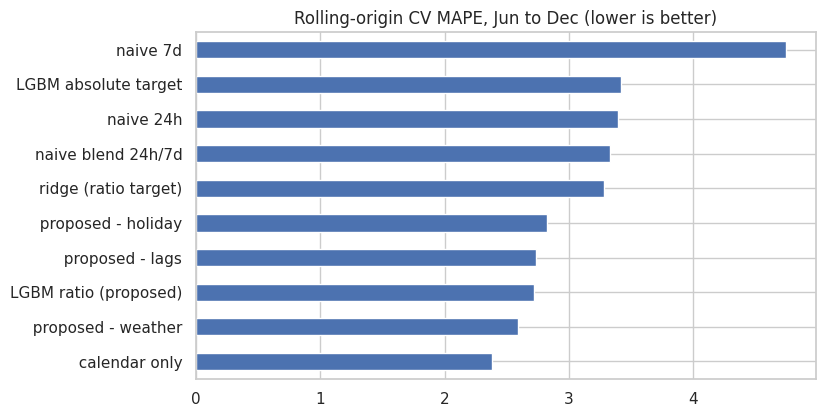

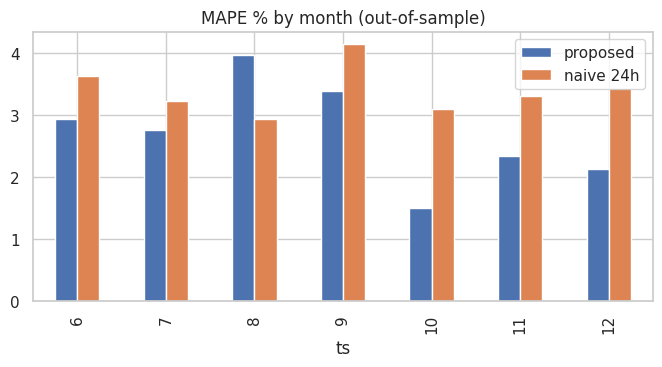

ts,6,7,8,9,10,11,12
proposed,2.94,2.75,3.97,3.39,1.50,2.34,2.14
naive 24h,3.63,3.23,2.94,4.14,3.09,3.30,3.43


,holiday blocks,top-5% peaks,weekends
naive 24h,3.760,2.457,4.265
ridge (ratio target),4.386,2.724,3.063
LGBM absolute target,3.694,5.746,3.034
LGBM ratio (proposed),3.832,2.420,2.483
proposed - holiday,3.511,2.858,2.486


In [24]:
abl['MAPE_%'].sort_values().plot.barh(figsize=(8, 4.5)); plt.title('Rolling-origin CV MAPE, Jun to Dec (lower is better)'); plt.show()
prop = oof['LGBM ratio (proposed)']; nv = oof['naive 24h']
# By month: where does the model help and where not?
bym = pd.DataFrame({'proposed': ((prop - y).abs() / y * 100).groupby(y.index.month).mean(),
                    'naive 24h': ((nv - y).abs() / y * 100).groupby(y.index.month).mean()}).dropna()
bym.plot.bar(figsize=(8, 3.5)); plt.title('MAPE % by month (out-of-sample)'); plt.show(); display(bym.round(2).T)
is_hol = hf.reindex(data.index.normalize()).is_hol.values.astype(bool); peak = (y > y.quantile(.95)).values
subs = {'holiday blocks': is_hol, 'top-5% peaks': peak, 'weekends': np.asarray(data.index.dayofweek >= 5)}
display(pd.DataFrame({name: {k: metrics(y[m], oof[k][m])['MAPE_%'] for k in ['naive 24h', 'ridge (ratio target)', 'LGBM absolute target', 'LGBM ratio (proposed)', '  proposed - holiday']}
                      for name, m in subs.items()}))

**What the results tell us**

1. **"Same as yesterday" is hard to beat.** It scores 3.39%. Blending in last week barely helps (3.33%), and the linear model reaches 3.28%.
2. **Predicting the load level directly does not work well.** The same LightGBM trained on actual load values scores 3.41%, no better than copying yesterday. On the highest 5% of loads its error is more than double (5.7% against 2.4%), because in summer the load goes higher than anything it saw earlier in the year.
3. **Predicting the change from yesterday fixes this.** With the ratio target the same model scores **2.72%**, and the peaks are fine (2.4%). Weekends improve the most (2.5% against 4.3% for copying yesterday), because "yesterday" is often a weekday while "today" is a weekend, and the model learns that step.
4. **It wins in six of the seven months.** August is the exception (3.97% against 2.94%), the first month of the rainy season, which it had not seen before. More years of data should help.
5. **The extra information did not help.** Without the weather columns the error falls to 2.59%. Without the holiday columns it rises slightly to 2.82%. The simplest version, using only time of day and day of week, is the best of all at **2.38%**. On holiday days the full model (3.8%) is no better than copying yesterday (3.8%). With only one year of data (about 37 holidays and one pass through each season), there is not enough to learn reliable weather or holiday effects, and the extra columns mostly add noise.

The next cell makes this choice formally, so we do not just pick the winner by eye.

In [25]:
cal = GROUPS['calendar']
hol_c = [c for c in ['is_hol', 'hol_lag48', 'hol_lag336'] if c in X_all]
wx_c = [c for c in ['temp', 'temp_d24', 'hum_d24', 'temp_d168', 'cdd', 'cloud'] if c in X_all]
FEATURE_SETS = {'calendar only': cal,
                'calendar + holiday (compact)': cal + hol_c,
                'calendar + weather (core)': cal + wx_c,
                'calendar + scale-free lags': cal + GROUPS['lags'],
                'calendar + holiday + weather (compact)': cal + hol_c + wx_c,
                'full (all groups)': ALL_FEATS}
rows = []
for nm, fs in FEATURE_SETS.items():
    sel = rolling_oof(X_all, y, fs, mk_lgb, base=base, months=range(6, 10))       # selection folds
    tst = rolling_oof(X_all, y, fs, mk_lgb, base=base, months=range(10, 13))      # untouched hold-out
    rows.append({'feature set': nm, 'n_features': len(fs), 'MAPE Jun-Sep (selection)': metrics(y, sel)['MAPE_%'], 'MAPE Oct-Dec (hold-out)': metrics(y, tst)['MAPE_%']})
fs_table = pd.DataFrame(rows).set_index('feature set'); display(fs_table)
SELECTED = fs_table['MAPE Jun-Sep (selection)'].idxmin(); SELECTED_FEATS = FEATURE_SETS[SELECTED]
print('Selected on Jun-Sep CV:', SELECTED, '(%d features)' % len(SELECTED_FEATS))

,n_features,MAPE Jun-Sep (selection),MAPE Oct-Dec (hold-out)
feature set,,,
calendar only,7,2.717,1.932
calendar + holiday (compact),10,2.812,2.104
calendar + weather (core),13,3.147,2.086
calendar + scale-free lags,13,2.981,1.918
calendar + holiday + weather (compact),16,3.161,2.164
full (all groups),36,3.263,1.988


Selected on Jun-Sep CV: calendar only (7 features)


**Result of the selection.** Judged only on June to September, the simplest set wins: calendar only, at 2.72%. Every set that includes weather is clearly worse (3.1% to 3.3%). The untouched October to December months agree: calendar only 1.93%, weather added 2.09%, everything 1.99%. Adding the ratio-style load history is a tie (1.92%).

**Final design.** A LightGBM model that predicts `load now / load yesterday` from calendar inputs, then multiplies by yesterday's load to get the forecast. We use shallow trees on purpose, because there is only one year of data.

**This does not mean weather is unimportant for electricity demand in general.** It means this one year of data cannot show it. Also, as noted in Section 5, the load may not come from the same climate as Dhanbad. Because the brief asks for weather and holidays, the full version (all weather, holiday and history inputs) is also trained and saved, so it can be compared again when more data is available.

## 9. Hyper-parameter selection and final hold-out test (Milestone 3)

Now we fine-tune the model's settings. To keep the final test honest, the settings are picked using **June to September only**. The **October to December** months are scored once at the end, and nothing was chosen using them.

In [26]:
grid = [dict(num_leaves=nl, learning_rate=lr, n_estimators=ne, min_child_samples=mcs)
        for nl in (7, 15, 31) for lr, ne in ((0.05, 300), (0.03, 600)) for mcs in (60, 120)]
rows = []
for g in grid:
    p = {**LGB_PARAMS, **g}
    o = rolling_oof(X_all, y, SELECTED_FEATS, lambda: lgb.LGBMRegressor(**p), base=base, months=range(6, 10))
    rows.append({**g, **metrics(y, o)})
tune = pd.DataFrame(rows).sort_values('MAPE_%'); display(tune.head(6))
BEST = {k: (int(v) if k != 'learning_rate' else float(v)) for k, v in tune.iloc[0][['num_leaves', 'learning_rate', 'n_estimators', 'min_child_samples']].items()}
FINAL_PARAMS = {**LGB_PARAMS, **BEST}; print('chosen:', BEST)

,num_leaves,learning_rate,n_estimators,min_child_samples,MAPE_%,MAE,RMSE,n
0,7,0.05,300,60,2.698,2024.6,3136.5,5856
1,7,0.05,300,120,2.698,2024.3,3136.9,5856
2,7,0.03,600,60,2.701,2026.4,3138.3,5856
3,7,0.03,600,120,2.701,2026.8,3138.6,5856
5,15,0.05,300,120,2.714,2037.5,3149.8,5856
4,15,0.05,300,60,2.715,2038.1,3149.4,5856


chosen: {'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 300, 'min_child_samples': 60}


The six best settings all land within about 0.02 percentage points of each other (2.70% to 2.72%), so the exact settings barely matter. We take the simplest one: shallow trees with 7 leaves.

,MAPE_%,MAE,RMSE,n
"LGBM ratio, tuned (Oct-Dec test)",1.936,1221.9,1775.8,4368.0
naive 24h,3.272,2056.1,3139.0,4368.0
naive 7d,2.982,1900.9,2632.0,4368.0
ridge (ratio target),2.630,1653.0,2301.5,4368.0


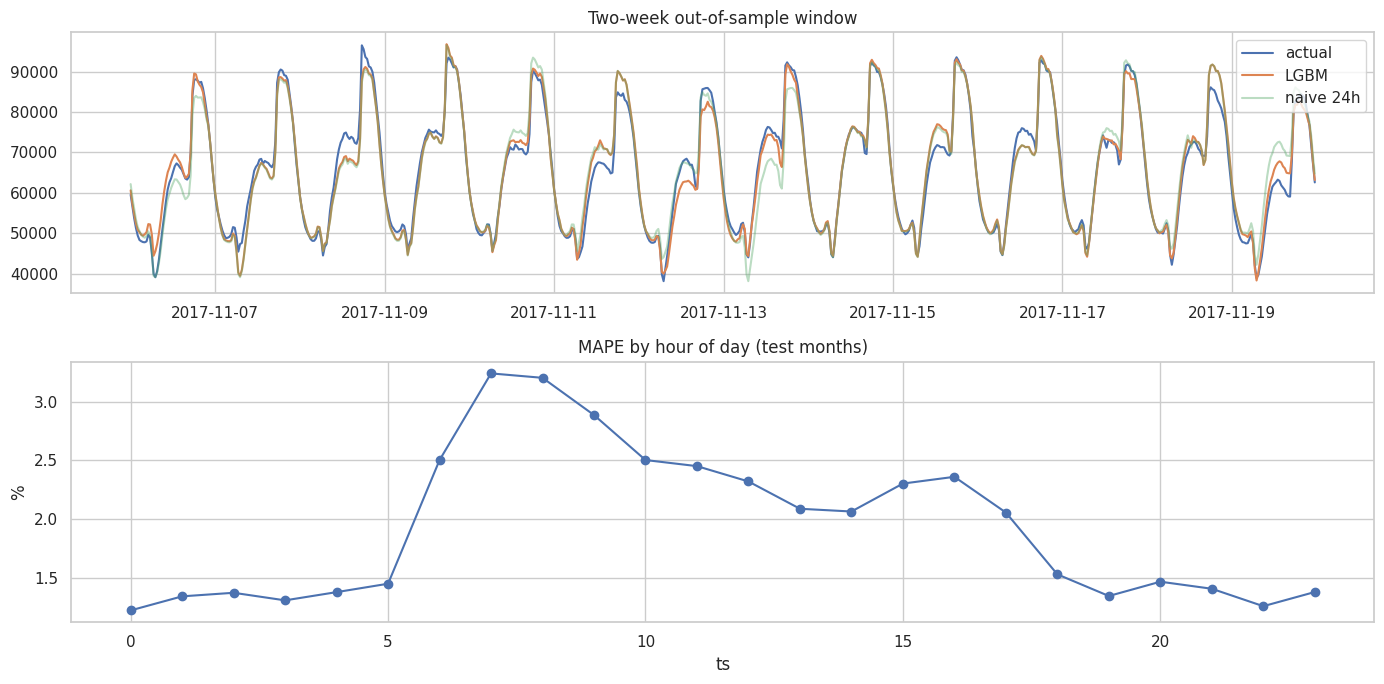

In [27]:
oof_test = rolling_oof(X_all, y, SELECTED_FEATS, lambda: lgb.LGBMRegressor(**FINAL_PARAMS), base=base, months=range(10, 13))
mk_ = oof_test.notna()
test_res = {'LGBM ratio, tuned (Oct-Dec test)': metrics(y, oof_test),
            'naive 24h': metrics(y[mk_], X_all['lag48'][mk_]), 'naive 7d': metrics(y[mk_], X_all['lag336'][mk_]),
            'ridge (ratio target)': metrics(y[mk_], oof['ridge (ratio target)'][mk_])}
display(pd.DataFrame(test_res).T)
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
wk = slice('2017-11-06', '2017-11-19')
ax[0].plot(y[wk], label='actual'); ax[0].plot(oof_test[wk], label='LGBM'); ax[0].plot(X_all['lag48'][wk], alpha=.4, label='naive 24h'); ax[0].legend(); ax[0].set_title('Two-week out-of-sample window')
err = (oof_test - y).dropna(); err.abs().div(y[err.index]).groupby(err.index.hour).mean().mul(100).plot(ax=ax[1], marker='o')
ax[1].set_title('MAPE by hour of day (test months)'); ax[1].set_ylabel('%'); plt.tight_layout(); plt.show()

**Final test on October to December (never used for any choice).** The chosen model is off by **1.94%** on average. Last week's value gives 2.98%, a linear model 2.63%, and "same as yesterday" 3.27%. That is about **41% less error than copying yesterday**. In plain units the typical miss is about 1,200 on a typical load of 71,000 (the same units as the file).

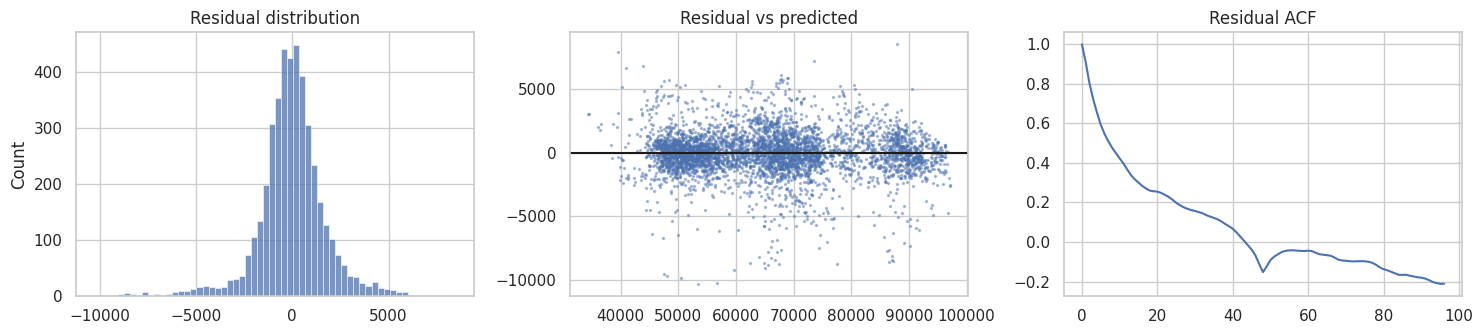

bias (mean residual): -48 | residual std: 1775


In [28]:
r = (y - oof_test).dropna()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(r, bins=60, ax=ax[0]); ax[0].set_title('Residual distribution')
ax[1].scatter(oof_test[r.index], r, s=2, alpha=.4); ax[1].axhline(0, c='k'); ax[1].set_title('Residual vs predicted')
ax[2].plot(acf(r, nlags=96, fft=True)); ax[2].set_title('Residual ACF')
plt.tight_layout(); plt.show()
print('bias (mean residual): %.0f | residual std: %.0f' % (r.mean(), r.std()))

**Are the errors balanced?** The average error is only -48 (essentially zero against a load of about 71,000), so the model is not leaning high or low. The typical spread of the errors is about 1,775, or 2.5% of the load.

## 10. Train the final models (Milestone 3)

Each of the four targets (total, F1, F2, F3) uses its own yesterday-baseline and is tested on October to December against its own "same as yesterday" forecast. Then every model is retrained on all available data for the final saved version. This is done for both the chosen feature set and the full feature set.

MAPE_%     MAE  naive24h_MAPE_%
target variant                                  
load   selected   1.936  1221.9            3.272
       full       1.989  1267.0            3.272
F1     selected   2.474   738.6            3.388
       full       2.573   768.4            3.388
F2     selected   3.462   754.8            5.579
       full       3.403   753.6            5.579
F3     selected   4.902   593.8            5.026
       full       4.882   594.3            5.026

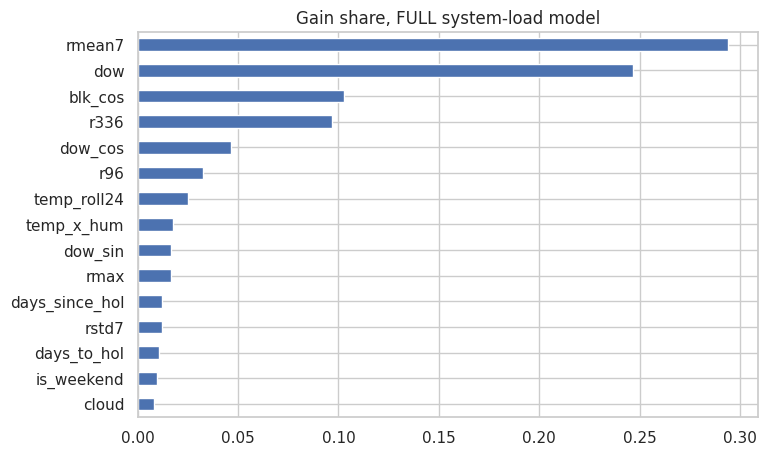

In [29]:
VARIANTS = {'selected': SELECTED_FEATS, 'full': ALL_FEATS}
final_models = {v: {} for v in VARIANTS}; scores = []
for name in ['load', 'F1', 'F2', 'F3']:
    Xt = build_features(data, hf, name, use_cloud=HAVE_CLOUD); yt = data[name]; bt = Xt['lag48']
    ok = Xt[ALL_FEATS + ABS_LAGS].notna().all(axis=1) & yt.notna()
    for vname, feats in VARIANTS.items():
        valid_backup = valid; valid = ok                    # rolling_oof reads the module-level mask
        o = rolling_oof(Xt, yt, feats, lambda: lgb.LGBMRegressor(**FINAL_PARAMS), base=bt, months=range(10, 13))
        valid = valid_backup
        m = o.notna(); sc = metrics(yt, o)
        scores.append({'target': name, 'variant': vname, 'MAPE_%': sc['MAPE_%'], 'MAE': sc['MAE'], 'naive24h_MAPE_%': metrics(yt[m], bt[m])['MAPE_%']})
        final_models[vname][name] = lgb.LGBMRegressor(**FINAL_PARAMS).fit(Xt.loc[ok, feats], (yt / bt)[ok])
display(pd.DataFrame(scores).set_index(['target', 'variant']))
imp = pd.Series(final_models['full']['load'].booster_.feature_importance('gain'), index=ALL_FEATS).sort_values(ascending=False)
(imp / imp.sum()).head(15).plot.barh(figsize=(8, 5)).invert_yaxis(); plt.title('Gain share, FULL system-load model'); plt.show()

**Per-feeder results (October to December).** The total improves from 3.27% to **1.94%**. F1 improves from 3.39% to 2.47%, and F2 from 5.58% to 3.46%. F3 barely improves (4.90% against 5.03%), because it is the most jumpy feeder and is hard to forecast from calendar information alone. The full feature set and the chosen set give almost the same results (for example 1.99% against 1.94% for the total), so the extra inputs neither help nor hurt much. Both are saved.

## 12. Summary, limits and next steps

**What we found**
* **The data:** the dates were mixed month-first styles (fixed), the 10-minute grid is complete, and only about 0.1% of readings were isolated glitches (replaced). The file's wind sensor and its own weather columns are not trustworthy, and the weather columns do not match Dhanbad (Section 5).
* **The pattern:** load is almost a copy of itself 24 hours earlier, so the useful question is "how will tomorrow differ from today?".
* **The model:** a small LightGBM that predicts that ratio. On three months it never saw, it is off by **1.94%** on average, against 3.27% for copying yesterday and 2.63% for a linear model. For feeders the gain is smaller: F1 2.5% (3.4% for copying), F2 3.5% (5.6%), F3 4.9% (5.0%, hardly better, because F3 is the jumpiest).
* **Weather and holidays:** adding them did not help on this one year, even with real Dhanbad weather, so the final model uses calendar inputs only. The full version is saved alongside.

**Limits to keep in mind**
* Only one year of data: summer-to-rainy-season behaviour (August) and most holiday types are barely learned.
* The holiday dates were compiled without the official notification and must be verified, especially the moon-based festivals.
* Training used weather that was measured after the fact (reanalysis), while the live backend will use weather forecasts, so small differences are expected.
* The load file's own weather suggests it may have been recorded in a different climate from Dhanbad. If so, Dhanbad weather would explain little of it, which fits what we saw. We cannot confirm this from the data.

